# Cross-modal Learning: Adapting TERRA to H&E with CellBridge

Transfer **TERRA’s molecular representations** to **H&E images** with **CellBridge**. Using paired H&E–Xenium data, train **LoRA adapters** and an alignment head on frozen **UNI2-h** to match TERRA embeddings. Then fit a cell-type classifier and calibrate ontology-aware predictions with **Cell-Ontology-Fallback (COF)**.

**You will:**
1. Load pretrained CellBridge weights.
2. Optionally prepare TERRA targets for UNI2-h adaptation (HEST-1k).
3. Extract H&E features and fit a cell-type classifier (NuCLS).
5. Generate ontology-aware prediction sets with the COF module.
6. Optionally conduct qualitative analysis.

:::{note}
A **GPU is recommended** for image encoding and **TERRA requires an NVIDIA GPU** for optional target preparation.
:::

## 1. Setup

From the repository root, create and activate a **Python 3.11** environment:

```bash
python3.11 -m venv .venv
source .venv/bin/activate
```
Install a [PyTorch build for your GPU](https://pytorch.org/get-started/locally/), then install CellBridge along with the notebook dependencies in the activated environment:

```bash
python -m pip install -e '.[models,preprocess,analysis]'
python -m pip install -r requirements/encoders.txt
python -m ipykernel install --user --name cellbridge --display-name 'CellBridge (Python 3.11)'
python -m jupyterlab notebooks/TUTORIAL.ipynb
```

For the optional TERRA section, also install `python -m pip install terra-st` following the [TERRA installation guide](https://terra-st.readthedocs.io/en/latest/installation.html).

Request access to [UNI2-h](https://huggingface.co/MahmoodLab/UNI2-h), accept the [HEST-1k dataset terms](https://huggingface.co/datasets/MahmoodLab/hest), and download the [CellBridge adapter](https://huggingface.co/ogutsevda/cellbridge).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from huggingface_hub import hf_hub_download

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/train/lora/cellbridge.yaml").is_file())
WORK = ROOT / "outputs" / "tutorial"
PAIRED = WORK / "data/train/hest"
NUCLS = WORK / "data/eval/nucls"
WORK.mkdir(parents=True, exist_ok=True)
print("Imports ready. Checking GPU availability...", flush=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PREPARE_PAIRED = True

os.environ.update({
    "CELLBRIDGE_ROOT": str(ROOT),
    "CELLBRIDGE_DATA_ROOT": str(WORK / "data"),
    "CELLBRIDGE_OUTPUTS_ROOT": str(WORK / "results"),
    "CELLBRIDGE_CHECKPOINTS_ROOT": str(WORK / "checkpoints"),
})
print(f"Device: {DEVICE} | Outputs: {WORK}")

Imports ready. Checking GPU availability...
Device: cuda | Outputs: /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial


In [2]:
from huggingface_hub import get_token, notebook_login

if get_token() is None:
    notebook_login()

## 2. (Optional) Cross-modal alignment of TERRA and UNI2-h

If you set `PREPARE_PAIRED = False`, then you can skip this part, and directly use CellBridge in the next section.

If you would like to learn about the multi-modal pretraining step, please set `PREPARE_PAIRED = True`, and follow the example with two sections from HEST-1k below. You can also use custom paired datasets!

Below, we will download `NCBI876` (train) and `NCBI861` (validation), and extract TERRA cell embeddings. Check the [TERRA quickstart](https://terra-st.readthedocs.io/en/latest/notebooks/zero_shot_quickstart.html) for further details.

In [3]:
# Download registered H&E and transcripts, then reconstruct raw cell counts.
if PREPARE_PAIRED:
    import yaml
    from huggingface_hub import snapshot_download

    HEST_RAW = WORK / "hest_raw"
    sample_ids = ["NCBI876", "NCBI861"]
    snapshot_download(
        "MahmoodLab/hest", repo_type="dataset", local_dir=str(HEST_RAW),
        allow_patterns=["HEST_v1_3_0.csv"] + [
            name for sid in sample_ids for name in (
                f"wsis/{sid}.tif", f"transcripts/{sid}_transcripts.parquet",
            )
        ],
    )
    hest_meta = pd.read_csv(HEST_RAW / "HEST_v1_3_0.csv", low_memory=False).set_index("id")
    PAIRED.mkdir(parents=True, exist_ok=True)
    manifest = pd.DataFrame([{
        "id": sid,
        "wsi": str(HEST_RAW / f"wsis/{sid}.tif"),
        "transcripts": str(HEST_RAW / f"transcripts/{sid}_transcripts.parquet"),
        "pixel_size_um": float(hest_meta.loc[sid, "pixel_size_um_estimated"]),
        "output_dir": str(PAIRED / sid),
    } for sid in sample_ids])
    manifest.to_csv(PAIRED / "manifest.csv", index=False)
    pd.DataFrame({
        "sample_id": sample_ids, "split": ["distill_train", "distill_val"],
    }).to_csv(PAIRED / "splits.csv", index=False)
    PREPROCESS_CONFIG = WORK / "preprocess.yaml"
    PREPROCESS_CONFIG.write_text(yaml.safe_dump({
        "output_root": str(PAIRED), "qv_threshold": 20,
    }))
    display(manifest[["id", "pixel_size_um"]])

if PREPARE_PAIRED:
    for sid in sample_ids:
        print(f"Reconstructing counts for {sid}...", flush=True)
        result = subprocess.run([
            sys.executable, "-m", "cellbridge.preprocess.02_quality_check_streaming",
            "--config", str(PREPROCESS_CONFIG), "--sample-id", sid,
        ], capture_output=True, text=True)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

wsis/NCBI861.tif:   0%|          | 0.00/394M [00:00<?, ?B/s]

transcripts/NCBI876_transcripts.parquet:   0%|          | 0.00/172M [00:00<?, ?B/s]

HEST_v1_3_0.csv: 0.00B [00:00, ?B/s]

wsis/NCBI876.tif:   0%|          | 0.00/257M [00:00<?, ?B/s]

transcripts/NCBI861_transcripts.parquet:   0%|          | 0.00/265M [00:00<?, ?B/s]

,id,pixel_size_um
0,NCBI876,0.2125
1,NCBI861,0.2125


Reconstructing counts for NCBI876...
Reconstructing counts for NCBI861...


In [4]:
# Match retained cell IDs to H&E centers before exporting the 384-dimensional TERRA targets.
if PREPARE_PAIRED:
    import anndata as ad
    from terra import download_pretrained, harmonize_adata, tokenize_adata, embed_dataset

    MAX_TEACHER_CELLS = 2_000  # Demo targets per section.
    TOKEN_CACHE = Path("/tmp") / f"cellbridge-{os.getuid()}" / "terra_tokens"
    TOKEN_CACHE.mkdir(parents=True, exist_ok=True)

    assert torch.cuda.is_available(), "Run TERRA in an NVIDIA GPU environment."
    terra_dir = Path(download_pretrained("Lotfollahi-lab/TERRA-112M"))

if PREPARE_PAIRED:
    for sid in sample_ids:
        sample_dir = PAIRED / sid
        adata = ad.read_h5ad(sample_dir / f"{sid}.h5ad")
        assert adata.obs_names.is_unique
        adata.obs["cell_id"] = adata.obs_names.astype(str)
        # Harmonize raw counts against TERRA's gene vocabulary.
        harmonized = harmonize_adata(
            adata,
            gene_mapping_dict_file_path=str(terra_dir / "ensembl_dictionary.pkl"),
            gene_occurrence_count_file_path=str(terra_dir / "gene_count_dictionary.pkl"),
            min_cells_per_gene=10, min_genes_per_cell=10,
        )
        # Build neighborhoods from the full section before selecting demo targets.
        tokens = tokenize_adata(
            adata=harmonized, model_folder_path=str(terra_dir),
            cache_directory_path=str(TOKEN_CACHE / sid), nproc=4,
            keep_in_memory=True,
        )
        tokens = tokens.shuffle(seed=0).select(range(min(MAX_TEACHER_CELLS, len(tokens))))
        print(f"{sid}: embedding {len(tokens):,} target cells", flush=True)
        # Run frozen TERRA, then export the selected cell-level alignment targets.
        teacher = embed_dataset(
            dataset=tokens, model_folder_path=str(terra_dir), batch_size=128, num_workers=4,
        )
        cell_ids = np.asarray(tokens["cell_id"], dtype=str)
        centers = harmonized.obs.loc[cell_ids, ["he_x", "he_y"]]
        features = np.asarray(teacher["cell_emb"], dtype=np.float32)
        assert len(np.unique(cell_ids)) == len(cell_ids)
        assert features.shape == (len(cell_ids), 384)
        assert np.isfinite(features).all() and np.isfinite(centers.to_numpy()).all()
        np.savez(
            sample_dir / f"{sid}_terra.npz", cell_ids=cell_ids, cell_emb=features,
            he_x=centers.he_x.to_numpy(), he_y=centers.he_y.to_numpy(),
        )
        print(f"{sid}: saved {features.shape} teacher features")

/tmp/so25-cellbridge/venv/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/tmp/so25-cellbridge/venv/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

INFO:terra.inference.harmonize:STEP 1: DATA VALIDATION...
INFO:terra.inference.harmonize:Checking that adata.X contains raw counts...
INFO:terra.inference.harmonize:✓ adata.X contains raw counts (integer values).
INFO:terra.inference.harmonize:STEP 2: ADDING ENSEMBL IDS...
INFO:terra.inference.harmonize:Adding ensembl IDs from gene_mapping_dict with file path `/nfs/users/nfs_s/so25/.cache/huggingface/hub/models--Lotfollahi-lab--TERRA-112M/snapshots/00d1c977e49364ba10c28692abcbd102e115bf91/ensembl_dictionary.pkl`...
INFO:terra.inference.harmonize:Number of genes with matching ensembl IDs: 340.
INFO:terra.inference.harmonize:Filtering genes that have not occurred enough during pretraining...
INFO:terra.inference.harmonize:STEP 3: BASIC QUALITY CONTROL...
INFO:terra.inference.harmonize:Filtering cells with less than 10 genes.
INFO:terra.inference.harmonize:Before cell filtering: 12915 cells.
INFO:terra.inference.harmonize:After cell filtering: 12894 cells (removed 21 cells).
INFO:terra.in

/tmp/so25-cellbridge/venv/lib/python3.11/site-packages/terra/preprocessors/graph.py:26: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata,


INFO:terra.tokenizers.cell_tokenizers:Retrieving tokens for neighborhood cells.
INFO:terra.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:terra.tokenizers.cell_tokenizers:Using generator for dataset creation.
INFO:terra.tokenizers.cell_tokenizers:Formatting gene tokens...


...

INFO:terra.tokenizers.cell_tokenizers:Retrieving tokens for neighborhood cells.
INFO:terra.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:terra.tokenizers.cell_tokenizers:Using generator for dataset creation.
INFO:terra.tokenizers.cell_tokenizers:Formatting gene tokens...


Map (num_proc=4):   0%|          | 0/43877 [00:00<?, ? examples/s]

NCBI861: embedding 2,000 target cells
INFO:terra.inference.embed:STEP 1: LOADING CONFIG...
INFO:terra.inference.embed:STEP 2: GENERATING EMBEDDINGS...
INFO:terra.utils.helper:Protein-init: DISABLED -- using the default learnable nn.Embedding for gene tokens.
INFO:terra.utils.helper:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(13, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384,

0it [00:00, ?it/s]/tmp/so25-cellbridge/venv/lib/python3.11/site-packages/terra/inference/embed.py:265: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
16it [01:26,  5.39s/it]

NCBI861: saved (2000, 384) teacher features


The history saving thread hit an unexpected error (OperationalError('unable to open database file')).History will not be written to the database.


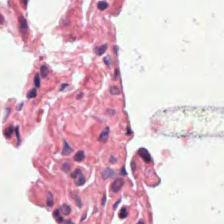

In [5]:
# Preview a paired crop: 112 × 112 µm resized to 224 × 224 pixels.
if PREPARE_PAIRED:
    from cellbridge.train.lora.data import crop_cell, open_wsi

    sid = sample_ids[0]
    row = manifest.set_index("id").loc[sid]
    with np.load(PAIRED / sid / f"{sid}_terra.npz", allow_pickle=False) as saved:
        cx, cy = float(saved["he_x"][0]), float(saved["he_y"][0])
    wsi = open_wsi(row.wsi)
    try:
        display(crop_cell(wsi, cx, cy, row.pixel_size_um))
    finally:
        wsi.store.close()

In [6]:
# Write an illustrative training config and print its command. This is only a simple example!
if PREPARE_PAIRED:
    import shlex
    from cellbridge.config import load_config

    train_cfg = load_config(ROOT / "configs/train/lora/cellbridge.yaml")
    train_cfg.update({
        "run_name": "tutorial_hest",
        "data_root": str(PAIRED), "splits_path": str(PAIRED / "splits.csv"),
        "output_dir": str(WORK / "training"),
        "checkpoint_dir": str(WORK / "checkpoints/tutorial_hest"),
        "max_cells_per_sample": 5000, "max_val_cells_per_sample": 2000,
    })
    train_cfg["training"].update({"max_steps": 20000, "eval_every": 1000, "patience": 5})
    TRAIN_CONFIG = WORK / "train.yaml"
    TRAIN_CONFIG.write_text(yaml.safe_dump(train_cfg, sort_keys=False))
    print(shlex.join(["cellbridge-train", "--config", str(TRAIN_CONFIG)]))

cellbridge-train --config /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial/train.yaml


The **representative** training update is shown below:

```python
from cellbridge.train.lora.data import build_datasets
from cellbridge.train.lora.model import build_uni2_distiller, contrastive_loss
from cellbridge.train.lora.train import make_loader, make_optimizer

student = build_uni2_distiller(**train_cfg['model']).to(DEVICE)
train_data, val_data = build_datasets(train_cfg, student.eval_transforms)
loader = make_loader(train_data, train_cfg, training=True)
optimizer, _ = make_optimizer(student, train_cfg)
student.train()
for batch in loader:
    optimizer.zero_grad(set_to_none=True)
    image_z = student(batch['image'].to(DEVICE))['projected']
    target_z = student.project_terra(batch['terra'].to(DEVICE))
    loss = contrastive_loss(image_z, target_z, temperature=0.07)['loss_total']
    loss.backward()
    optimizer.step()
train_data.close()
val_data.close()
```

## 3. Download CellBridge and prepare NuCLS

Download the CellBridge adapter and UNI2-h weights. The extraction step loads the model when needed.

In [7]:
LOCAL_CHECKPOINT = None
RELEASE = "1c334ee0783be5aaae93a5562522d73fc92ee6c1"
uni_weights = hf_hub_download("MahmoodLab/UNI2-h", filename="pytorch_model.bin")
checkpoint_path = Path(LOCAL_CHECKPOINT) if LOCAL_CHECKPOINT else Path(hf_hub_download(
    "ogutsevda/cellbridge", filename="cellbridge.pt", revision=RELEASE,
))
print(f"CellBridge checkpoint: {checkpoint_path}")
print(f"UNI2-h weights: {uni_weights}")

CellBridge checkpoint: /nfs/users/nfs_s/so25/.cache/huggingface/hub/models--ogutsevda--cellbridge/snapshots/1c334ee0783be5aaae93a5562522d73fc92ee6c1/cellbridge.pt
UNI2-h weights: /nfs/users/nfs_s/so25/.cache/huggingface/hub/models--MahmoodLab--UNI2-h/snapshots/d517a8dd47902dd7c308b3c36f63bce47e7b9a43/pytorch_model.bin


This command downloads the NuCLS dataset along with its cell-level annotations and prepares the fixed train/validation/test split!

,annotated_cells
split,
test,7150
train,33972
val,18363


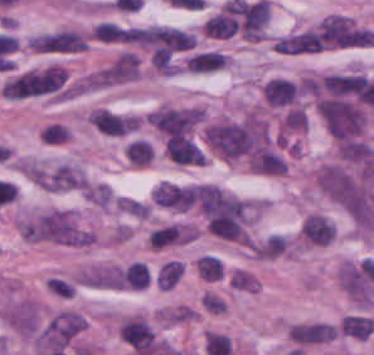

In [8]:
CONFIG = ROOT / "configs/inference/nucls.yaml"
RUN = WORK / "results/nucls"

prepared = (
    (NUCLS / "nucls_info.csv").is_file()
    and (NUCLS / "splits/train_test_val_split.csv").is_file()
    and (NUCLS / "raw/rgb").is_dir()
    and (NUCLS / "raw/csv").is_dir()
)

if prepared:
    print("Using the existing prepared NuCLS dataset.")
else:
    subprocess.run(
        [sys.executable, "-m", "cellbridge.inference.prepare.nucls", str(NUCLS)],
        check=True,
    )

metadata = pd.read_csv(NUCLS / "nucls_info.csv", dtype={"row_id": str})
display(metadata.groupby("split").size().rename("annotated_cells").to_frame())
with Image.open(NUCLS / "raw/rgb" / metadata.iloc[42]["image_name"]) as image:
    display(image.copy())

## 4. Check inputs and extract embeddings

We extract CellBridge features and run a simple linear probe. `check` validates the inputs and the checkpoint from the previous sections, whereas, `extract` loads UNI2-h in a separate process, applies that adapter, and saves one embedding per cell.

In [9]:
def infer(stage):
    subprocess.run([
        sys.executable, "-m", "cellbridge.inference.run", stage,
        "--config", str(CONFIG), "--method", "cellbridge",
        "--arm", "lora_adapted", "--probe", "linear",
        "--checkpoint", str(checkpoint_path),
        "--output-dir", str(RUN), "--device", DEVICE,
    ], check=True)

infer("check")

Conformal: alpha=0.1, 51,345/51,970 mapped cells
Bootstrap: 22 independent test groups
nucls: 51,970 cells, 1741 labeled samples
Methods: cellbridge
Tasks: all
Probes: linear
Output: /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial/results/nucls


In [ ]:
infer("extract")

In [11]:
manifest = pd.read_csv(RUN / "embeddings/lora_adapted/manifest.csv")
print(f"Saved {manifest.n_cells.sum():,} cell embeddings across {len(manifest)} images.")
display(manifest[["sample_id", "n_cells", "n_features"]].head())

Saved 51,970 cell embeddings across 1741 images.


,sample_id,n_cells,n_features
0,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,32,1536
1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,42,1536
2,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,25,1536
3,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,36,1536
4,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,30,1536


## 5. Evaluate the classifier

`evaluate` fits a logistic regression classifier using the saved embeddings and reports held-out test performance.

In [12]:
infer("evaluate")
EVAL = RUN / "evaluation/lora_adapted/all/linear"
metrics = pd.read_csv(EVAL / "metrics.csv")
display(metrics[["macro_f1", "balanced_accuracy", "macro_auroc"]].round(3))

[cellbridge/lora_adapted/all/linear] macro_f1=0.4114, bootstrap_se=0.0282


,macro_f1,balanced_accuracy,macro_auroc
0,0.411,0.407,0.92


## 6. Calibrate and evaluate COF

`conformal` fits a separate classifier on training cells and uses validation cells for calibration.
It evaluates prediction sets on test cells at a target coverage of **90%**.
Ontology mapping and minimum class support can exclude cells from this stage.
CellBridge's **Cell-Ontology-Fallback (COF)** method corresponds to `branch_graph` below!

In [13]:
infer("conformal")
COF = EVAL / "conformal_prediction"
cof_metrics = pd.read_csv(COF / "metrics.csv")
display(cof_metrics.loc[cof_metrics.conformal_method == "branch_graph", [
    "marginal_coverage", "mean_prediction_set_size", "singleton_rate",
]].round(3))

Excluded classes with fewer than 20 cells per split: duct epithelial cell, endothelial cell, eosinophil, myoepithelial cell, neutrophil
[cellbridge/lora_adapted/all/linear/conformal_prediction] coverage=0.9218, size=1.97


,marginal_coverage,mean_prediction_set_size,singleton_rate
2,0.953,2.724,0.395


## 7. (Optional) Qualitative analysis

You can visualize the reliability scores after the COF module for the cell of your choice!

Overlays use NuCLS polygons, boxes, and points. Reliability is `1 − set size / number of classes`, not a probability; empty sets are gray.

In [14]:
with np.load(COF / "predictions.npz", allow_pickle=False) as saved:
    classes = saved["classes"].astype(str)
    sets = saved["branch_graph_sets"]
    predictions = pd.DataFrame({
        "row_id": saved["ids"].astype(str),
        "true_label": saved["y_true"].astype(str),
        "predicted_label": classes[saved["probabilities"].argmax(axis=1)],
        "prediction_set": [", ".join(classes[mask]) for mask in sets],
        "set_size": sets.sum(axis=1),
    })

# Join by saved cell identity, not by CSV row order.
predictions = predictions.merge(
    metadata[["row_id", "image_name"]], on="row_id", validate="one_to_one",
)
display(predictions.head(10))
print(f"All results are saved under {RUN}")

,row_id,true_label,predicted_label,prediction_set,set_size,image_name
0,0,tumor cell,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
1,1,tumor cell,tumor cell,"fibroblast, lymphocyte, macrophage, plasma cel...",5,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
2,2,tumor cell,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
3,3,tumor cell,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
4,4,tumor cell,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
5,5,tumor cell,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
6,6,tumor cell,tumor cell,"fibroblast, lymphocyte, macrophage, plasma cel...",5,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
7,7,tumor cell,tumor cell,"fibroblast, lymphocyte, macrophage, plasma cel...",5,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
8,8,tumor cell,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
9,9,tumor cell,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...


All results are saved under /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial/results/nucls


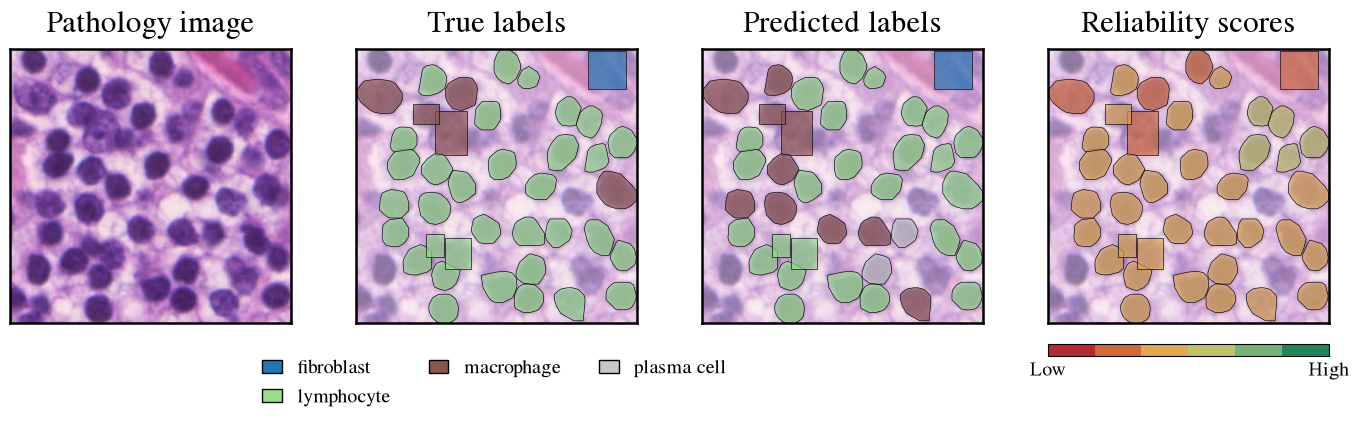

In [15]:
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, to_rgba_array
from matplotlib.patches import Patch

# Change this test image to inspect another field of view.
image_name = ("TCGA-OL-A66I-DX1_id-5ea40973ddda5f839897bc9c_"
              "left-42229_top-24987_bottom-25286_right-42535.png")
cells = predictions.loc[predictions.image_name == image_name].merge(
    metadata[["row_id", "cell_id", "x", "y"]], on="row_id", validate="one_to_one",
)
assert not cells.empty, "Choose an image with saved test predictions."
with Image.open(NUCLS / "raw/rgb" / image_name) as image:
    tissue = np.asarray(image.convert("RGB"))
# cell_id indexes the original annotation rows; preserve their shapes.
annotations = pd.read_csv(NUCLS / "raw/csv" / Path(image_name).with_suffix(".csv"))
annotations = annotations.iloc[cells.cell_id.to_numpy(int)]
points = annotations["type"].eq("point").to_numpy()
polygons = [np.column_stack([np.fromstring(row.coords_x, sep=","),
                            np.fromstring(row.coords_y, sep=",")])
            for row in annotations.loc[~points].itertuples()]

colours = dict(zip(classes, plt.get_cmap("tab20")(np.linspace(0, 1, len(classes)))))
cmap = LinearSegmentedColormap.from_list(
    "reliability", ["#B52B32", "#D97A38", "#E5C65B", "#8ABF7B", "#20865C"], N=len(classes) + 1,
)
scale = plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap=cmap)
reliability = scale.to_rgba(1 - cells.set_size / len(classes))
reliability[cells.set_size.eq(0)] = to_rgba_array("gray")[0]
fills = [cells.true_label.map(colours), cells.predicted_label.map(colours), reliability]

with plt.rc_context({"font.family": "STIXGeneral", "text.usetex": False, "pdf.fonttype": 42}):
    fig, axes = plt.subplots(1, 4, figsize=(14, 4.5))
    fig.subplots_adjust(left=0.02, right=0.99, top=0.85, bottom=0.24, wspace=0.08)
    titles = ["Pathology image", "True labels", "Predicted labels", "Reliability scores"]
    for i, (ax, title) in enumerate(zip(axes, titles)):
        ax.imshow(tissue, alpha=1 if i == 0 else 0.65)
        if i:
            faces = to_rgba_array(fills[i - 1], alpha=0.65)
            ax.add_collection(PolyCollection(polygons, facecolors=faces[~points],
                                             edgecolors="black", linewidths=0.45))
            ax.scatter(cells.loc[points, "x"], cells.loc[points, "y"], c=faces[points],
                       s=24, edgecolors="black", linewidths=0.45)
        ax.set(xticks=[], yticks=[], xlim=(-0.5, tissue.shape[1] - 0.5),
               ylim=(tissue.shape[0] - 0.5, -0.5))
        ax.set_title(title, fontsize=22, pad=12)
        for spine in ax.spines.values():
            spine.set_linewidth(1.8)
    present = set(cells.true_label) | set(cells.predicted_label)
    handles = [Patch(facecolor=colours[label], edgecolor="black", label=label)
               for label in classes if label in present]
    if cells.set_size.eq(0).any():
        handles.append(Patch(facecolor="gray", edgecolor="black", label="Empty set"))
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.38, 0.20),
               ncol=3, frameon=False, fontsize=14, handlelength=1)
    bar = fig.colorbar(scale, cax=axes[3].inset_axes([0, -0.12, 1, 0.045]),
                       orientation="horizontal", ticks=[0, 1])
    bar.set_ticklabels(["Low", "High"])
    bar.ax.tick_params(length=0, labelsize=14)
    plt.show()
